# GCC-PHAT

This code utilises the GCC-PHAT (Generalised Cross Correlation Phase Transform) in order to determine the time difference of arrival between the two microphones. This method will likely be used for the microphone array based methods, as it can better scale to multiple microphones.

https://documentation.dspconcepts.com/awe-designer/8.D.2.6/generalized-cross-correlation-direction-of-arrival

The difference between this cross correlation function and the other FFT cross correlation function i was using is that this function exclusively looks at the phase of each frequency. It sets all magnitudes to 1 "cross /= (np.abs(cross) + 1e-12)" so all thats left is the phase part of the complex number returned by the calculation of "cross". This is then what gets used to compute the lags. A time shift in the time domain directly corresponds to a phase shift in the frequency domain.. We no longer care about the room information, the level differences, spectrum of the source.. We only look at the delay information.

In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "../Audio_Files/HATS/"

recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")
    
print(recordings)

{'H1': {'-90': {'L': PosixPath('../Audio_Files/HATS/H1/-90/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-90/R.wav')}, '-67.5': {'L': PosixPath('../Audio_Files/HATS/H1/-67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-67.5/R.wav')}, '-45': {'L': PosixPath('../Audio_Files/HATS/H1/-45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-45/R.wav')}, '-22.5': {'L': PosixPath('../Audio_Files/HATS/H1/-22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-22.5/R.wav')}, '0': {'L': PosixPath('../Audio_Files/HATS/H1/0/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/0/R.wav')}, '22.5': {'L': PosixPath('../Audio_Files/HATS/H1/22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/22.5/R.wav')}, '45': {'L': PosixPath('../Audio_Files/HATS/H1/45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/45/R.wav')}, '67.5': {'L': PosixPath('../Audio_Files/HATS/H1/67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/67.5/R.wav')}, '90': {'L': PosixPath('../Audio_Files/HATS/H1/90/L.wav'), 'R': PosixPath('../Au

{'H1': {'-90': {'expected': '-90', 'calculated': np.float64(-90.0)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-71.8821898638341)}, '-45': {'expected': '-45', 'calculated': np.float64(-38.89260654344047)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-16.490405930801895)}, '0': {'expected': '0', 'calculated': np.float64(-2.33990284863558)}, '22.5': {'expected': '22.5', 'calculated': np.float64(90.0)}, '45': {'expected': '45', 'calculated': np.float64(61.80323225010033)}, '67.5': {'expected': '67.5', 'calculated': np.float64(90.0)}, '90': {'expected': '90', 'calculated': np.float64(87.80025751483869)}}, 'H2': {'-90': {'expected': '-90', 'calculated': np.float64(-83.45257409948249)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-55.642115197714496)}, '-45': {'expected': '-45', 'calculated': np.float64(-33.70978794239421)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-9.379227334410151)}, '0': {'expected': '0', 'calculated': np.float64(14.10

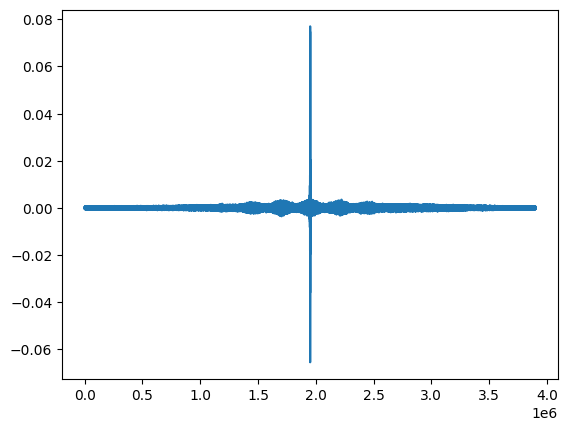

In [2]:
d = 0.21
c = 343
r = 0.0875 

def gcc_phat(x, y):
    n = len(x) + len(y) - 1
    X = np.fft.rfft(x, n=n)
    Y = np.fft.rfft(y, n=n)
    cross = X * np.conj(Y)
    cross /= (np.abs(cross) + 1e-12)
    result = np.fft.irfft(cross)
    return np.fft.fftshift(result)



def woodworth_itd(angle_deg, r=r, c=343.0):
    theta = np.radians(angle_deg)
    if abs(theta) <= np.pi/2:
        return (r / c) * (np.sin(theta) + theta)
    else:
        return (r / c) * (np.sign(theta) * np.pi - theta + np.sin(theta))

def itd_to_angle(itd_s, r=r, c=343.0):
    max_itd = ((r / c) * (np.pi / 2 + 1) * fs * 1.5)
    itd_s = np.clip(itd_s, -max_itd, max_itd)
    f = lambda theta: (r/c) * (np.sin(theta) + theta) - itd_s
    try:
        return np.degrees(brentq(f, -np.pi/2 + 1e-6, np.pi/2 - 1e-6))
    except ValueError:
        return np.sign(itd_s) * 90.0

results = {}

for height, angle_dict in recordings.items():
    results[height] = {}
    for angle, files in angle_dict.items():
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
    
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
    
        click_offset = R_click_idx - L_click_idx 

        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]

        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]


        correlation = gcc_phat(L_Trimmed, R_Trimmed)
        
        half = len(correlation) // 2
        lags = np.arange(-half, half + 1)[:len(correlation)]
        
        max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
        mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
        itd_samples = lags[mask][np.argmax(correlation[mask])]
        itd_seconds = itd_samples / fs
        
        angle_deg = itd_to_angle(itd_seconds)

        itd_expected = woodworth_itd(float(angle))
        
        results[height][angle] = {'expected': angle, 'calculated': angle_deg}   
        
print(results)  

plt.plot(correlation)

H1: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H1: calculated=[np.float64(-90.0), np.float64(-71.8821898638341), np.float64(-38.89260654344047), np.float64(-16.490405930801895), np.float64(-2.33990284863558), np.float64(90.0), np.float64(61.80323225010033), np.float64(90.0), np.float64(87.80025751483869)]
H2: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H2: calculated=[np.float64(-83.45257409948249), np.float64(-55.642115197714496), np.float64(-33.70978794239421), np.float64(-9.379227334410151), np.float64(14.10853868420995), np.float64(31.17211407601786), np.float64(58.67610562553954), np.float64(90.0), np.float64(90.0)]
H3: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H3: calculated=[np.float64(-90.0), np.float64(-11.73886533001672), np.float64(0.0), np.float64(-18.88671288529941), np.float64(16.490405930801895), np.float64(71.8821898638341), np.float64(26.186447448454544), np.float64(79.38096251876942), np.float64(9

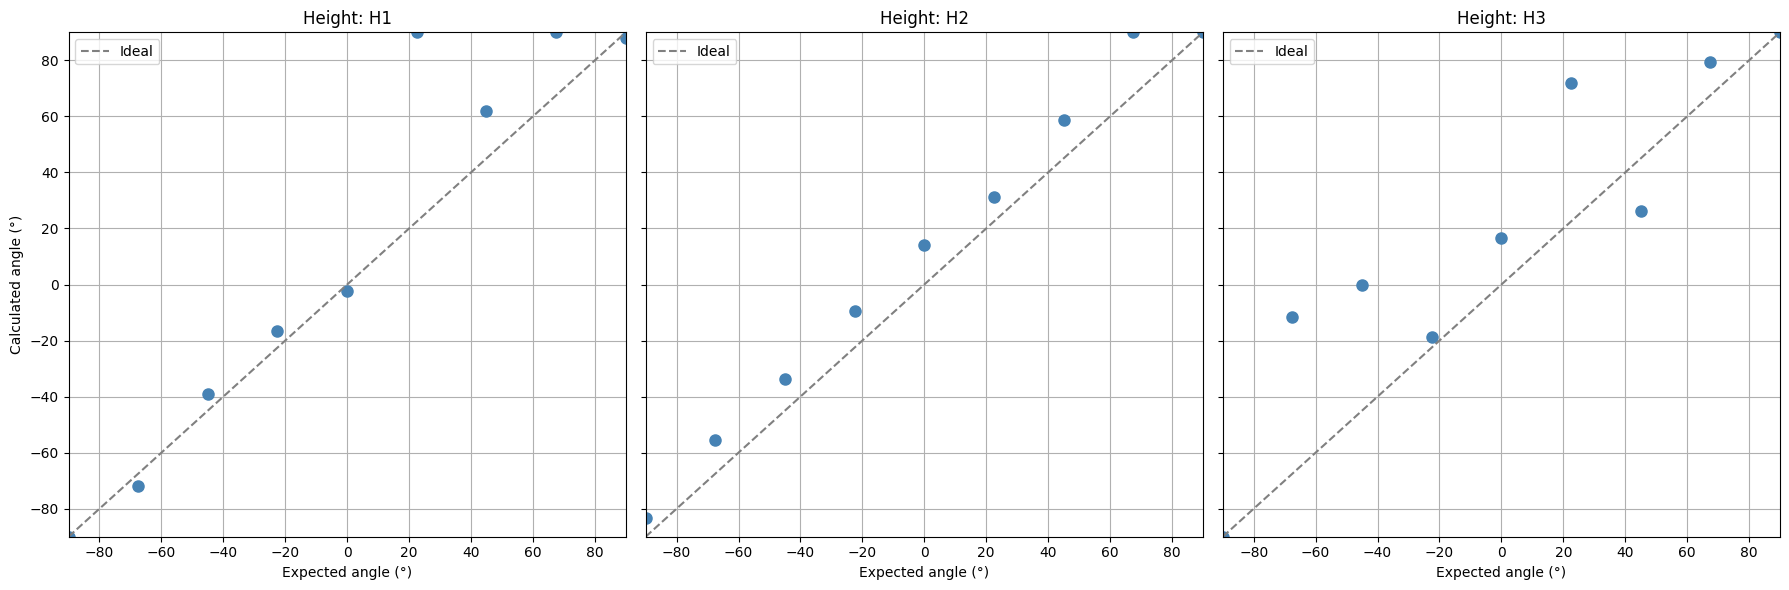

In [3]:
n_heights = 3

fig, axes = plt.subplots(1, n_heights, figsize=(6*n_heights, 6), sharex=True, sharey=True)

if n_heights == 1:
    axes = [axes]

for ax, height in zip(axes, heights):
    angle_data = results[height]
    
    sorted_angles = sorted(angle_data.keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [angle_data[a]['calculated'] for a in sorted_angles]
    
    print(f"{height}: expected={expected}")
    print(f"{height}: calculated={calculated}")
    
    ax.plot(expected, calculated, 'o', color='steelblue', markersize=8)
    ax.plot([-90, 90], [-90, 90], '--', color='gray', label='Ideal')
    
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.set_xlim(-90, 90)
    ax.set_ylim(-90, 90)
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel('Calculated angle (°)')
plt.tight_layout()
plt.show()

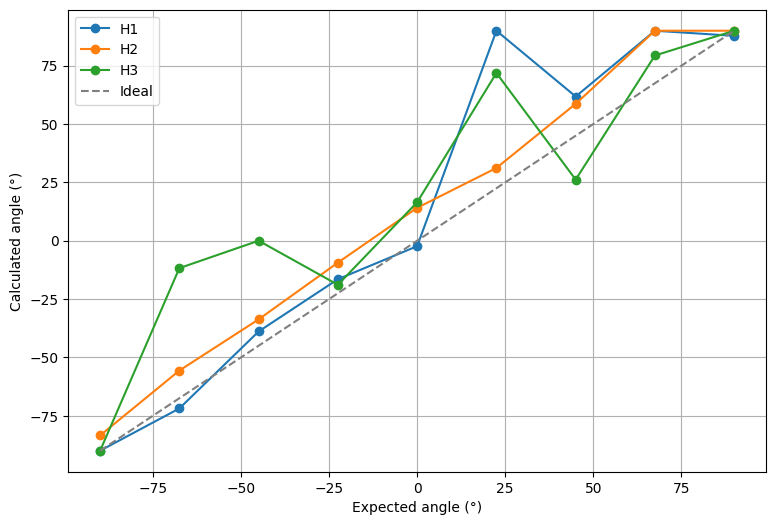

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for height in heights:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [results[height][a]['calculated'] for a in sorted_angles]
    ax.plot(expected, calculated, 'o-', label=height)
ax.plot([-90,90],[-90,90],'--', color='gray', label='Ideal')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Calculated angle (°)')
ax.legend(); ax.grid(True)
plt.show()

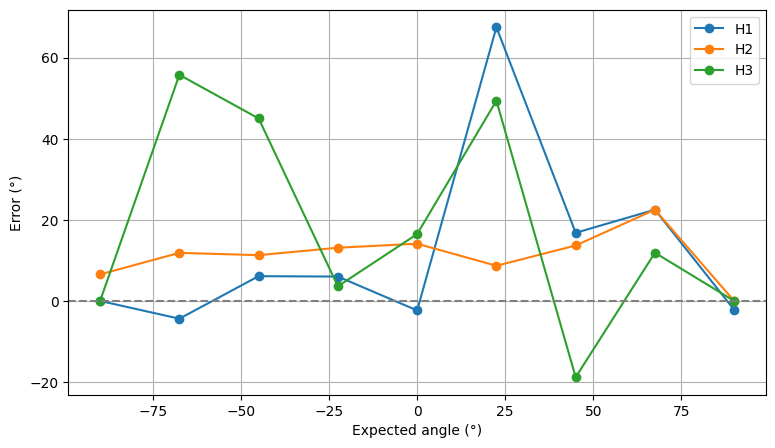

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for height in heights:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    error = [results[height][a]['calculated'] - float(a) for a in sorted_angles]
    ax.plot(expected, error, 'o-', label=height)
ax.axhline(0, color='gray', linestyle='--')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Error (°)')
ax.legend(); ax.grid(True)
plt.show()

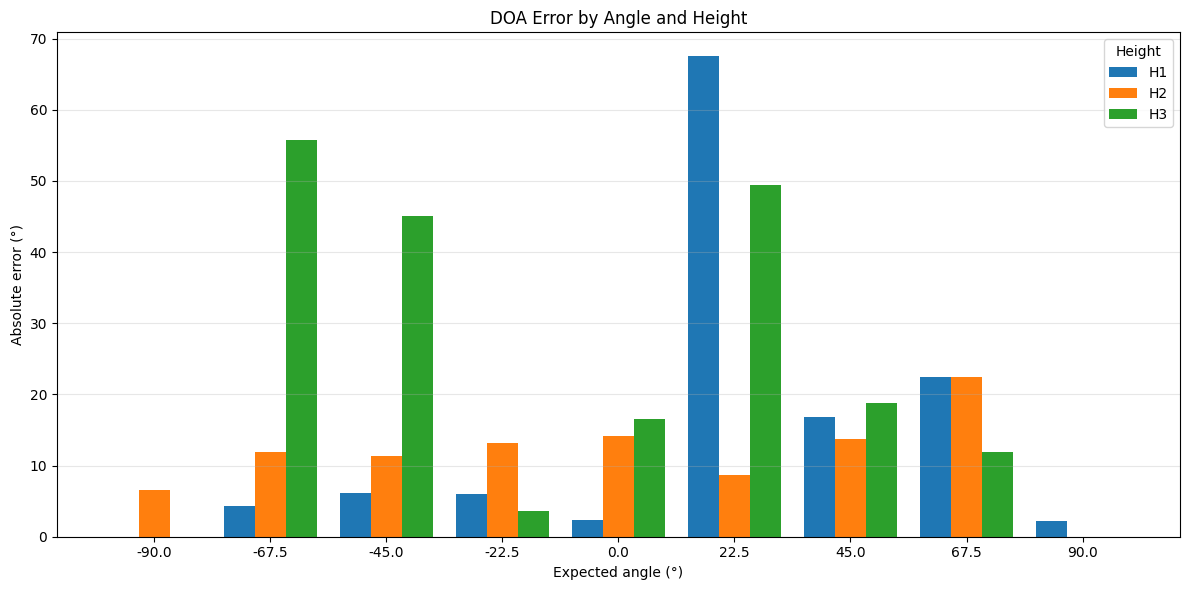

In [6]:
heights_list = list(results.keys())
angles_list = sorted([float(a) for a in results[heights_list[0]].keys()])

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(angles_list))
width = 0.8 / len(heights_list)

for i, height in enumerate(heights_list):
    errors = []
    for angle in angles_list:
        key = str(angle) if str(angle) in results[height] else str(int(angle))
        error = abs(results[height][key]['calculated'] - angle)
        errors.append(error)
    
    ax.bar(x + i*width, errors, width, label=height)

ax.set_xlabel('Expected angle (°)')
ax.set_ylabel('Absolute error (°)')
ax.set_title('DOA Error by Angle and Height')
ax.set_xticks(x + width * (len(heights_list)-1) / 2)
ax.set_xticklabels(angles_list)
ax.legend(title='Height')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()